In [1]:

import zipfile
import os

with zipfile.ZipFile('/content/archive.zip', 'r') as z:
    z.extractall('/content/zomato_data')

print("Extracted files:")
print(os.listdir('/content/zomato_data'))


Extracted files:
['zomato.csv']


In [2]:

import pandas as pd

df = pd.read_csv('/content/zomato_data/zomato.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())


Dataset loaded successfully!
Dataset shape: (56252, 13)

Column names:
['address', 'name', 'online_order', 'book_table', 'rate', 'votes', 'phone', 'location', 'rest_type', 'dish_liked', 'cuisines', 'approx_cost(for two people)', 'listed_in(type)']

First 5 rows:


,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),listed_in(type)
0,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,Buffet
1,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,Buffet
2,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,Buffet
3,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,Buffet
4,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,Buffet



Missing values:
address                           17
name                              16
online_order                      19
book_table                        58
rate                            7838
votes                             78
phone                           1296
location                         126
rest_type                        338
dish_liked                     28225
cuisines                         203
approx_cost(for two people)      521
listed_in(type)                 4610
dtype: int64


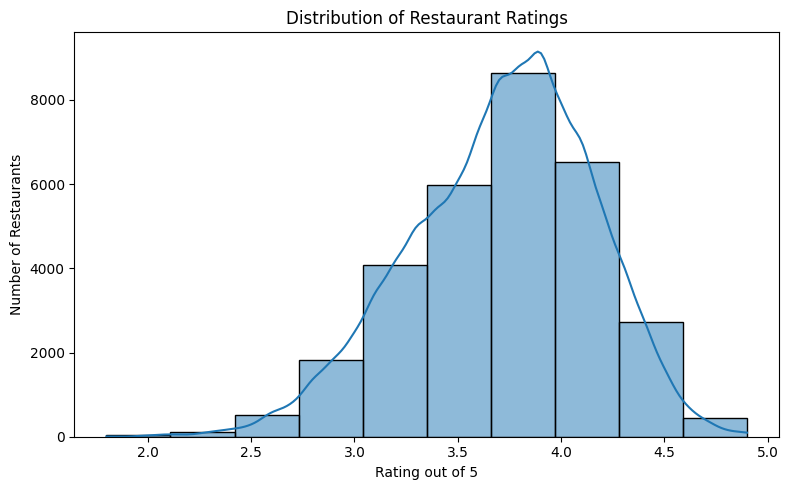

In [4]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(df_clean['rate'].dropna(), bins=10, kde=True)
plt.title('Distribution of Restaurant Ratings')
plt.xlabel('Rating out of 5')
plt.ylabel('Number of Restaurants')
plt.tight_layout()
plt.show()


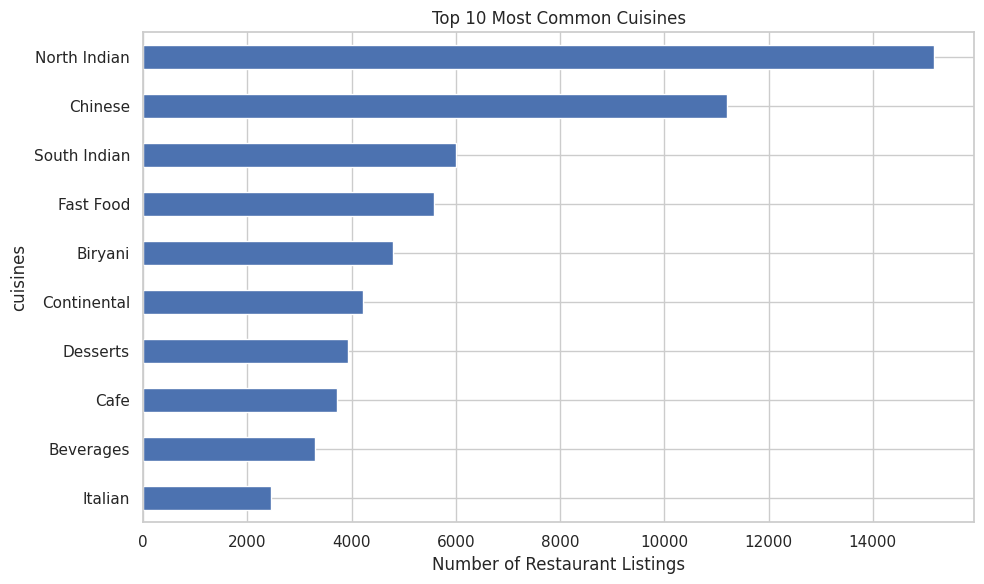

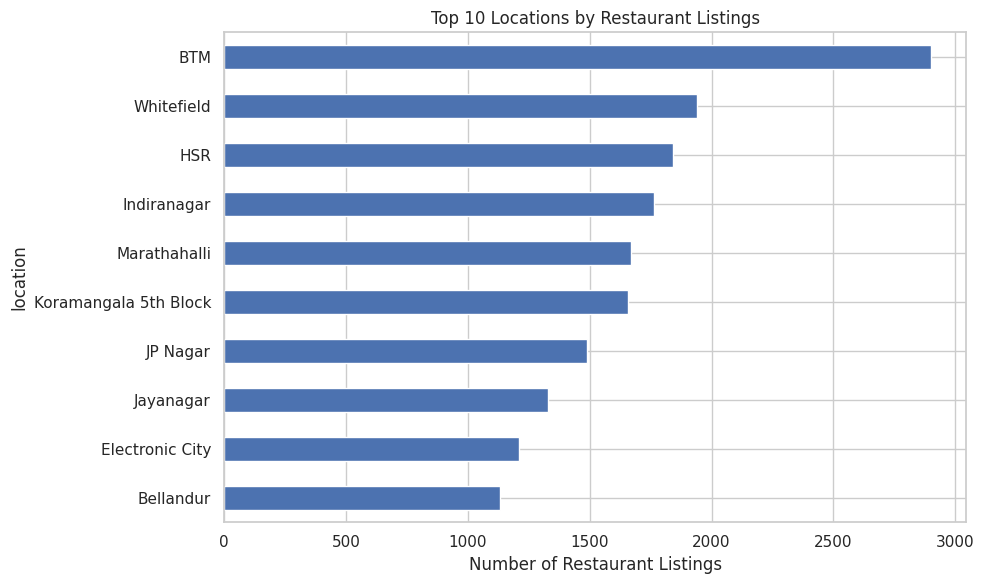

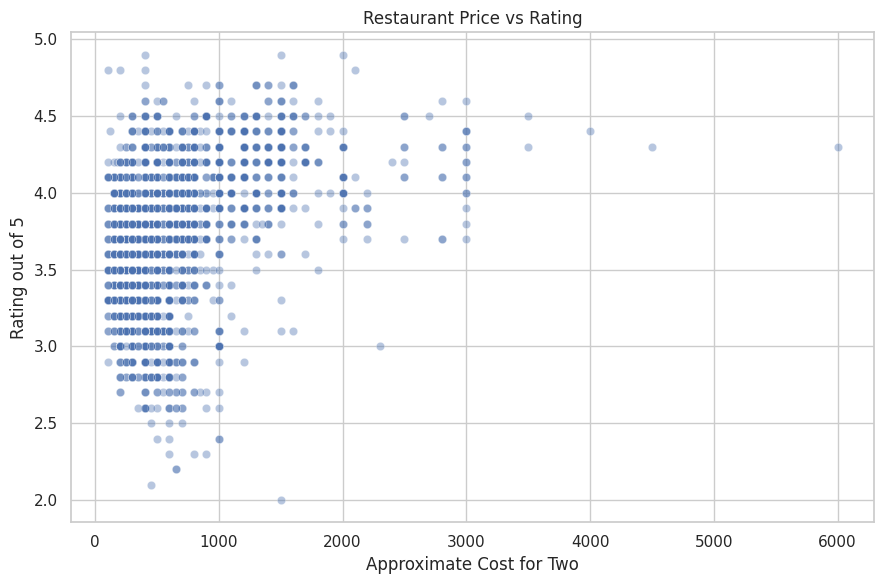

In [5]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid")

# 1. Top 10 most common cuisines
cuisine_data = (
    df_clean.dropna(subset=['cuisines'])
    .assign(cuisines=df_clean['cuisines'].str.split(','))
    .explode('cuisines')
)
cuisine_data['cuisines'] = cuisine_data['cuisines'].str.strip()

plt.figure(figsize=(10, 6))
cuisine_data['cuisines'].value_counts().head(10).sort_values().plot(
    kind='barh'
)
plt.title('Top 10 Most Common Cuisines')
plt.xlabel('Number of Restaurant Listings')
plt.tight_layout()
plt.show()

# 2. Top 10 restaurant locations
plt.figure(figsize=(10, 6))
df_clean['location'].value_counts().head(10).sort_values().plot(
    kind='barh'
)
plt.title('Top 10 Locations by Restaurant Listings')
plt.xlabel('Number of Restaurant Listings')
plt.tight_layout()
plt.show()

# 3. Price vs restaurant rating
price_col = 'approx_cost(for two people)'
price_data = df_clean.dropna(subset=['rate', price_col])

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=price_data.sample(min(3000, len(price_data)), random_state=42),
    x=price_col, y='rate', alpha=0.4
)
plt.title('Restaurant Price vs Rating')
plt.xlabel('Approximate Cost for Two')
plt.ylabel('Rating out of 5')
plt.tight_layout()
plt.show()


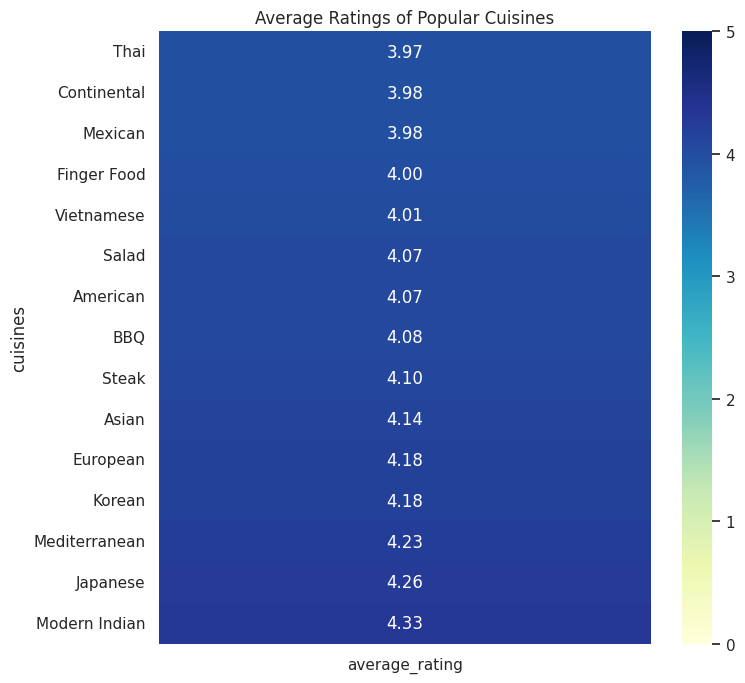

Top-rated cuisines with at least 100 listings:


,average_rating,restaurant_count
cuisines,,
Modern Indian,4.329630,108
Japanese,4.257940,233
Mediterranean,4.231043,393
Korean,4.179048,105
European,4.178958,518
Asian,4.144835,910
Steak,4.096235,425
BBQ,4.077778,540
American,4.072500,1000


In [6]:

# Calculate average ratings for cuisines
cuisine_ratings = (
    cuisine_data.dropna(subset=['rate'])
    .groupby('cuisines')
    .agg(
        average_rating=('rate', 'mean'),
        restaurant_count=('rate', 'size')
    )
)

# Keep cuisines with at least 100 listings
top_cuisines = cuisine_ratings[
    cuisine_ratings['restaurant_count'] >= 100
].sort_values('average_rating', ascending=False).head(15)

plt.figure(figsize=(8, 7))
sns.heatmap(
    top_cuisines[['average_rating']].sort_values('average_rating'),
    annot=True, fmt='.2f', cmap='YlGnBu',
    vmin=0, vmax=5
)
plt.title('Average Ratings of Popular Cuisines')
plt.tight_layout()
plt.show()

print("Top-rated cuisines with at least 100 listings:")
display(top_cuisines)


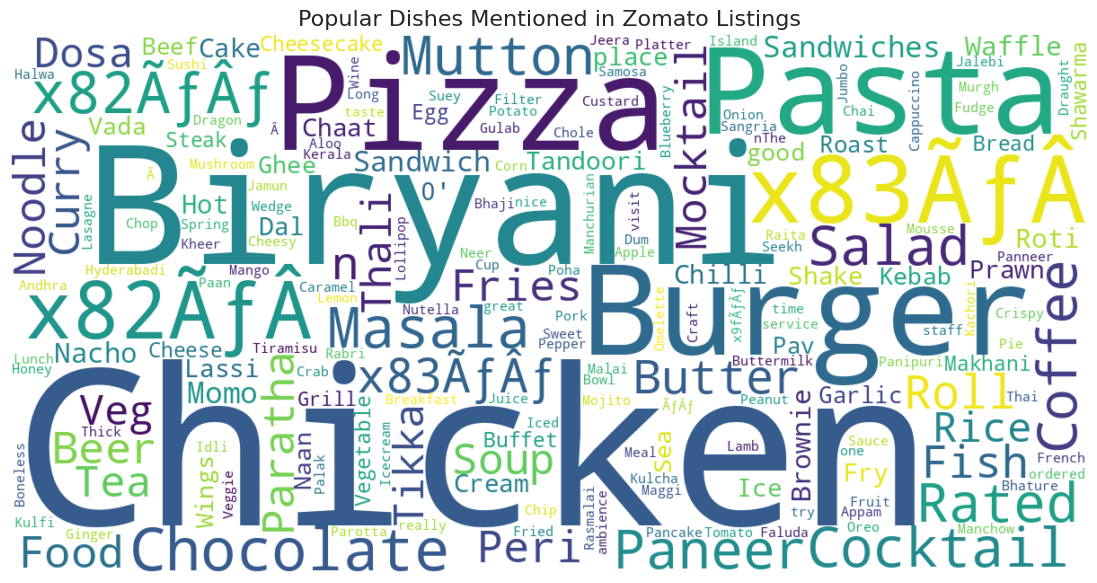

In [8]:

!pip -q install wordcloud

from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

# Combine all dish descriptions into one text
dish_text = ' '.join(
    df_clean['dish_liked'].dropna().astype(str)
)

# Generate word cloud
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    stopwords=STOPWORDS,
    collocations=False
).generate(dish_text)

# Display visualization
plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Popular Dishes Mentioned in Zomato Listings', fontsize=16)
plt.show()


In [9]:

print("""
BUSINESS RECOMMENDATIONS FOR A FOOD PLATFORM

1. Restaurant Partnerships:
Partner with highly rated restaurants in popular locations
to improve customer choice and platform credibility.

2. Cuisine-Based Discovery:
Create cuisine categories and personalized recommendations
based on popular dishes and customer preferences.

3. Location-Based Promotions:
Promote restaurants in areas with fewer listings to help
customers discover more options and support local businesses.

4. Price-Based Recommendations:
Introduce budget, mid-range, and premium restaurant filters
to help customers choose according to their spending limits.

5. Improve Restaurant Quality:
Encourage restaurants with lower ratings to improve food
quality and service through customer feedback and monitoring.
""")



BUSINESS RECOMMENDATIONS FOR A FOOD PLATFORM

1. Restaurant Partnerships:
Partner with highly rated restaurants in popular locations
to improve customer choice and platform credibility.

2. Cuisine-Based Discovery:
Create cuisine categories and personalized recommendations
based on popular dishes and customer preferences.

3. Location-Based Promotions:
Promote restaurants in areas with fewer listings to help
customers discover more options and support local businesses.

4. Price-Based Recommendations:
Introduce budget, mid-range, and premium restaurant filters
to help customers choose according to their spending limits.

5. Improve Restaurant Quality:
Encourage restaurants with lower ratings to improve food
quality and service through customer feedback and monitoring.



## Business Recommendations for a Food Discovery Platform

1. **Restaurant Partnerships:** Partner with well-rated restaurants to improve the platform's restaurant selection and customer trust.

2. **Cuisine-Based Discovery:** Organize restaurants by cuisine and highlight popular dishes to help customers discover food that matches their preferences.

3. **Location-Based Promotions:** Use restaurant-density insights to identify areas where additional restaurant partnerships or local promotions may be useful.

4. **Price-Based Recommendations:** Offer budget, mid-range, and premium filters so customers can find restaurants that fit their spending limits.

5. **Restaurant Quality Improvement:** Encourage restaurants to monitor customer feedback and improve food quality and service where ratings indicate potential problems.

In [10]:

!pip -q install reportlab

import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image, PageBreak
)
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch

out = '/content/zomato_report_files'
os.makedirs(out, exist_ok=True)

price_col = 'approx_cost(for two people)'
valid = df_clean.dropna(subset=['rate'])
avg_rating = valid['rate'].mean()
median_price = df_clean[price_col].median()
top_location = df_clean['location'].mode().iloc[0]
top_cuisine = cuisine_data['cuisines'].value_counts().index[0]

# Save rating chart
plt.figure(figsize=(7, 4))
sns.histplot(valid['rate'], bins=10, kde=True)
plt.title('Distribution of Restaurant Ratings')
plt.tight_layout()
plt.savefig(out + '/ratings.png', dpi=150)
plt.close()

# Save location chart
plt.figure(figsize=(7, 4))
df_clean['location'].value_counts().head(10).sort_values().plot(kind='barh')
plt.title('Top 10 Restaurant Locations')
plt.tight_layout()
plt.savefig(out + '/locations.png', dpi=150)
plt.close()

# Save price-rating chart
price_data = df_clean.dropna(subset=['rate', price_col])
plt.figure(figsize=(7, 4))
sns.scatterplot(
    data=price_data.sample(min(2000, len(price_data)), random_state=42),
    x=price_col, y='rate', alpha=0.4
)
plt.title('Price vs Restaurant Rating')
plt.tight_layout()
plt.savefig(out + '/price_rating.png', dpi=150)
plt.close()

# Build PDF
pdf_path = '/content/Zomato_Analysis_Report.pdf'
doc = SimpleDocTemplate(
    pdf_path, pagesize=(8.27*inch, 11.7*inch),
    rightMargin=48, leftMargin=48, topMargin=42, bottomMargin=42
)

styles = getSampleStyleSheet()
styles.add(ParagraphStyle(
    name='CoverTitle', parent=styles['Title'],
    alignment=TA_CENTER, spaceAfter=18
))
story = []

story.append(Paragraph(
    'Zomato Restaurant Dataset Analysis', styles['CoverTitle']
))
story.append(Paragraph(
    'Data Science Internship Project', styles['Heading2']
))
story.append(Spacer(1, 12))

story.append(Paragraph('1. Project Overview', styles['Heading1']))
story.append(Paragraph(
    'This project explores restaurant listings to understand ratings, '
    'cuisine preferences, location hotspots, and restaurant prices. '
    'Python, Pandas, Matplotlib and Seaborn were used for data cleaning '
    'and visualization.', styles['BodyText']
))
story.append(Spacer(1, 10))

story.append(Paragraph('2. Dataset and Cleaning', styles['Heading1']))
story.append(Paragraph(
    f'The original dataset contains {len(df):,} rows and {df.shape[1]} '
    f'columns. After duplicate removal, {len(df_clean):,} rows remain. '
    'Text fields were trimmed, rating values were converted to numeric, '
    'and price and vote fields were converted where possible. Missing '
    'values were retained where needed for analysis rather than '
    'inventing replacement values.', styles['BodyText']
))
story.append(Spacer(1, 10))

story.append(Paragraph('3. Key Findings', styles['Heading1']))
findings = [
    f'Average available restaurant rating: {avg_rating:.2f} out of 5.',
    f'Median listed cost for two: {median_price:,.0f} (dataset currency units).'
        if pd.notna(median_price) else 'Median cost was unavailable.',
    f'Location with the most listings: {top_location}.',
    f'Most frequently listed cuisine category: {top_cuisine}.',
    'The rating distribution is concentrated mainly around the middle-to-high range.'
]
for finding in findings:
    story.append(Paragraph('• ' + finding, styles['BodyText']))
    story.append(Spacer(1, 5))

story.append(Spacer(1, 8))
story.append(Paragraph('4. Visual Analysis', styles['Heading1']))
for caption, filename in [
    ('Restaurant Rating Distribution', 'ratings.png'),
    ('Restaurant Location Hotspots', 'locations.png'),
    ('Restaurant Price vs Rating', 'price_rating.png')
]:
    story.append(Paragraph(caption, styles['Heading2']))
    story.append(Image(out + '/' + filename, width=6.1*inch, height=3.4*inch))
    story.append(Spacer(1, 10))

story.append(PageBreak())
story.append(Paragraph('5. Business Recommendations', styles['Heading1']))

recommendations = [
    ('Restaurant partnerships',
     'Partner with well-rated restaurants to strengthen selection and trust.'),
    ('Cuisine-based discovery',
     'Organize listings by cuisine and highlight popular dishes.'),
    ('Location-based promotions',
     'Use location hotspots to guide partnership and promotion efforts.'),
    ('Price-based recommendations',
     'Provide budget, mid-range and premium filters for different customers.'),
    ('Restaurant quality improvement',
     'Encourage restaurants to monitor feedback and improve service.')
]
for title, description in recommendations:
    story.append(Paragraph(title, styles['Heading2']))
    story.append(Paragraph(description, styles['BodyText']))
    story.append(Spacer(1, 8))

story.append(Paragraph('6. Conclusion', styles['Heading1']))
story.append(Paragraph(
    'This analysis demonstrates how restaurant listings can support '
    'data-informed decisions about restaurant discovery, pricing and '
    'partnerships. The findings describe this dataset and should not be '
    'treated as proof of customer preferences across every market. '
    'The word cloud, when included in the notebook, represents liked-dish '
    'descriptions rather than individual customer reviews.',
    styles['BodyText']
))

doc.build(story)
print('PDF report created:', pdf_path)


PDF report created: /content/Zomato_Analysis_Report.pdf


In [11]:

from google.colab import files
files.download('/content/Zomato_Analysis_Report.pdf')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:

import pandas as pd
import numpy as np

# Keep the original data safe
df_clean = df.copy()

# Clean column names
df_clean.columns = df_clean.columns.str.strip()

# Remove duplicate rows
df_clean.drop_duplicates(inplace=True)

# Clean text columns
for col in df_clean.select_dtypes(include='object').columns:
    df_clean[col] = df_clean[col].str.strip()

# Convert rating to numeric
df_clean['rate'] = (
    df_clean['rate'].astype(str)
    .str.replace('/5', '', regex=False)
    .str.strip()
    .replace(['NEW', '-', 'nan', ''], np.nan)
)
df_clean['rate'] = pd.to_numeric(df_clean['rate'], errors='coerce')

# Convert price to numeric
price_col = 'approx_cost(for two people)'
df_clean[price_col] = pd.to_numeric(
    df_clean[price_col].astype(str).str.replace(',', '', regex=False),
    errors='coerce'
)

# Convert votes to numeric
df_clean['votes'] = pd.to_numeric(
    df_clean['votes'], errors='coerce'
)

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())
print("\nCleaned data preview:")
display(df_clean.head())


Original rows: 56252
Cleaned rows: 40549

Missing values after cleaning:
address                            2
name                               1
online_order                       4
book_table                        38
rate                            9685
votes                           4147
phone                            808
location                          98
rest_type                        251
dish_liked                     18226
cuisines                         151
approx_cost(for two people)     4366
listed_in(type)                 2907
dtype: int64

Cleaned data preview:


,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),listed_in(type)
0,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1,775.0,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800.0,Buffet
1,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1,787.0,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800.0,Buffet
2,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8,918.0,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800.0,Buffet
3,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7,88.0,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300.0,Buffet
4,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8,166.0,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600.0,Buffet
